# Alzheimer MRI — Test Evaluation and Grad-CAM


## 1. Setup
Import libraries, set seeds, and configure compute device.


In [1]:
import os
from pathlib import Path
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Set seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Load Trained Model
Load the best checkpoint from `artifacts/best_efficientnet_b0.pth` without downloading weights.


In [2]:
# Resolve canonical checkpoint path
PROJECT_ROOT = Path('..') if Path('../data').exists() else Path('.')
checkpoint_path = PROJECT_ROOT / 'artifacts' / 'best_efficientnet_b0.pth'

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Trained checkpoint not found at: {checkpoint_path.resolve()}\n"
        "Please run notebooks/03_train_efficientnet.ipynb first to train the model."
    )

# Load checkpoint onto device
checkpoint = torch.load(checkpoint_path, map_location=device)
class_to_idx = checkpoint['class_to_idx']
idx_to_class = checkpoint['idx_to_class']
class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

# Instantiate fresh EfficientNet-B0 without downloading ImageNet weights
model = models.efficientnet_b0(weights=None)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, len(class_names))
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(device)
model.eval()

print("Model successfully loaded:")
print(f" - Source checkpoint: {checkpoint_path.resolve()}")
print(f" - Trained Epoch: {checkpoint['epoch']}")
print(f" - Best Val Macro F1: {checkpoint['val_f1']:.4f}")
print(f" - Classes ({len(class_names)}): {class_to_idx}")


Model successfully loaded:
 - Source checkpoint: C:\Users\usern\Desktop\Alzheimer-Detection\artifacts\best_efficientnet_b0.pth
 - Trained Epoch: 15
 - Best Val Macro F1: 0.9780
 - Classes (4): {'Mild_Demented': 0, 'Moderate_Demented': 1, 'Non_Demented': 2, 'Very_Mild_Demented': 3}


## 3. Recreate Exact Test Split
Reconstruct the identical 15% test split (960 images) using Phase 2 stratification.


In [3]:
# Locate dataset directory
if Path('data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')
elif Path('../data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('../data/Alzheimer (Preprocessed Data)')
else:
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')

# Collect all images and labels
image_paths = []
labels = []
IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}

for cls_name in class_names:
    folder = DATA_DIR / cls_name
    for file_path in folder.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTS:
            image_paths.append(file_path)
            labels.append(class_to_idx[cls_name])

# Stratified splits: 70% train, 15% validation, 15% test (identical to Phase 2 and 3)
_, temp_paths, _, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, random_state=RANDOM_SEED, stratify=labels
)
_, test_paths, _, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, random_state=RANDOM_SEED, stratify=temp_labels
)

print(f"Held-out test set size: {len(test_paths)} images")
test_counts = Counter(test_labels)
for i, cls_name in enumerate(class_names):
    print(f"  {cls_name:20s}: {test_counts[i]:4d} images ({test_counts[i]/len(test_paths)*100:.1f}%)")

# Deterministic test transforms (no data augmentation)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
test_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Dataset & DataLoader
class AlzheimerDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

test_dataset = AlzheimerDataset(test_paths, test_labels, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)


Held-out test set size: 960 images
  Mild_Demented       :  135 images (14.1%)
  Moderate_Demented   :    9 images (0.9%)
  Non_Demented        :  480 images (50.0%)
  Very_Mild_Demented  :  336 images (35.0%)


## 4. Evaluate Test Set
Run inference on the held-out test set and calculate predictions and probabilities.


In [4]:
all_preds = []
all_targets = []
all_probs = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)

overall_accuracy = accuracy_score(all_targets, all_preds)
print(f"Overall Test Accuracy: {overall_accuracy * 100:.2f}%")


Overall Test Accuracy: 95.52%


## 5. Per-Class Metrics and Specificity
Calculate per-class precision, recall, F1-score, and one-vs-rest specificity.


In [5]:
cm = confusion_matrix(all_targets, all_preds)
precision, recall, f1, support = precision_recall_fscore_support(all_targets, all_preds, average=None)

metrics_rows = []
for i, cls_name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    tn = cm.sum() - (tp + fp + fn)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    metrics_rows.append({
        'Class': cls_name,
        'Precision': round(precision[i], 4),
        'Recall': round(recall[i], 4),
        'F1-Score': round(f1[i], 4),
        'Specificity': round(specificity, 4),
        'Support': int(support[i])
    })

# Add macro and weighted averages
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro')
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='weighted')

metrics_rows.append({
    'Class': 'Macro Average',
    'Precision': round(macro_p, 4),
    'Recall': round(macro_r, 4),
    'F1-Score': round(macro_f1, 4),
    'Specificity': round(np.mean([r['Specificity'] for r in metrics_rows[:4]]), 4),
    'Support': int(len(all_targets))
})

metrics_rows.append({
    'Class': 'Weighted Average',
    'Precision': round(weighted_p, 4),
    'Recall': round(weighted_r, 4),
    'F1-Score': round(weighted_f1, 4),
    'Specificity': round(sum(r['Specificity'] * r['Support'] for r in metrics_rows[:4]) / len(all_targets), 4),
    'Support': int(len(all_targets))
})

df_metrics = pd.DataFrame(metrics_rows)
display(df_metrics)

# Scrutiny of the minority class Moderate_Demented
mod_idx = class_to_idx['Moderate_Demented']
mod_tp = cm[mod_idx, mod_idx]
mod_fn = cm[mod_idx, :].sum() - mod_tp
mod_fp = cm[:, mod_idx].sum() - mod_tp
print("\n--- Moderate_Demented Scrutiny (Small Minority Class) ---")
print(f"Total Test Images: {support[mod_idx]}")
print(f"True Positives:    {mod_tp}")
print(f"False Negatives:   {mod_fn}")
print(f"False Positives:   {mod_fp}")
print(f"Recall:            {mod_tp / support[mod_idx]:.4f} ({mod_tp}/{support[mod_idx]})")
print("Note: Because N=9, each single error shifts recall by 11.1%. Performance estimates carry higher variance.")


,Class,Precision,Recall,F1-Score,Specificity,Support
0,Mild_Demented,0.8986,0.9852,0.9399,0.9818,135
1,Moderate_Demented,1.0000,0.8889,0.9412,1.0000,9
2,Non_Demented,0.9685,0.9604,0.9644,0.9688,480
3,Very_Mild_Demented,0.9604,0.9375,0.9488,0.9792,336
4,Macro Average,0.9569,0.9430,0.9486,0.9824,960
5,Weighted Average,0.9561,0.9552,0.9553,0.9746,960



--- Moderate_Demented Scrutiny (Small Minority Class) ---
Total Test Images: 9
True Positives:    8
False Negatives:   1
False Positives:   0
Recall:            0.8889 (8/9)
Note: Because N=9, each single error shifts recall by 11.1%. Performance estimates carry higher variance.


## 6. Confusion Matrix Plot
Visualize true vs. predicted classifications across all 4 categories.


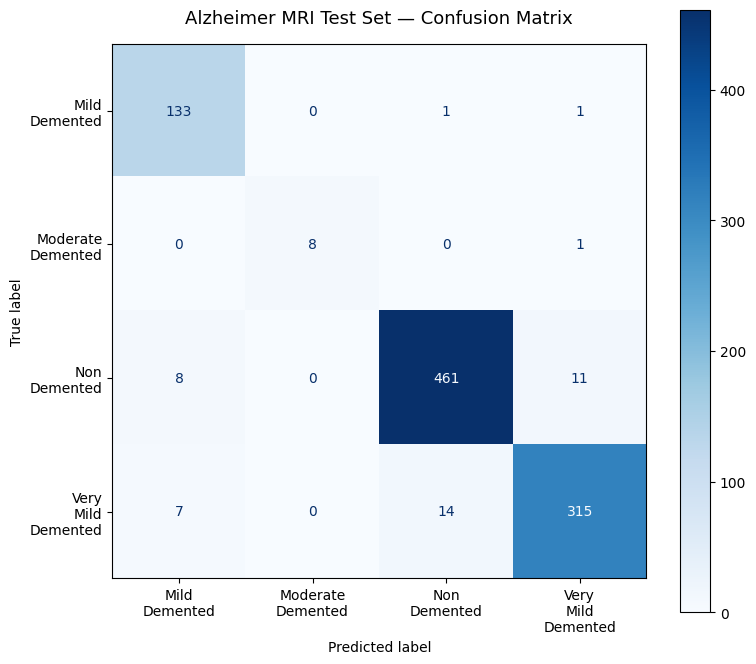

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[c.replace('_', '\n') for c in class_names])
disp.plot(cmap='Blues', ax=ax, colorbar=True, values_format='d')
plt.title('Alzheimer MRI Test Set — Confusion Matrix', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


## 7. Native PyTorch Grad-CAM Implementation
Implement Grad-CAM using hooks on the final convolutional layer of EfficientNet-B0 (`model.features[-1]`).


In [7]:
target_conv_layer = model.features[-1]

def generate_gradcam(model, target_layer, input_tensor, target_class=None):
    """Generates a normalized Grad-CAM heatmap for an input tensor."""
    activations = None
    gradients = None
    
    def forward_hook(module, inp, out):
        nonlocal activations
        activations = out
        
    def backward_hook(module, grad_in, grad_out):
        nonlocal gradients
        gradients = grad_out[0]
        
    f_handle = target_layer.register_forward_hook(forward_hook)
    b_handle = target_layer.register_full_backward_hook(backward_hook)
    
    model.zero_grad()
    input_tensor = input_tensor.clone().requires_grad_(True)
    logits = model(input_tensor)
    probs = F.softmax(logits, dim=1)
    
    if target_class is None:
        target_class = logits.argmax(dim=1).item()
        
    score = logits[0, target_class]
    score.backward()
    
    f_handle.remove()
    b_handle.remove()
    
    # Global Average Pooling of gradients
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations).sum(dim=1, keepdim=True)
    cam = F.relu(cam)
    cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    
    # Normalize to [0, 1]
    c_min, c_max = cam.min(), cam.max()
    if c_max > c_min:
        cam = (cam - c_min) / (c_max - c_min)
    else:
        cam = np.zeros_like(cam)
        
    return cam, target_class, probs.detach().cpu().numpy()[0]

def show_gradcam(image_path, true_label_idx, target_class=None):
    """Displays original scan, Grad-CAM heatmap, and overlay."""
    pil_img = Image.open(image_path).convert('RGB').resize((224, 224))
    input_tensor = test_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    
    heatmap, pred_idx, probs = generate_gradcam(model, target_conv_layer, input_tensor, target_class)
    
    true_name = idx_to_class[true_label_idx]
    pred_name = idx_to_class[pred_idx]
    confidence = probs[pred_idx] * 100
    
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    
    # 1. Original scan
    axes[0].imshow(pil_img, cmap='gray')
    axes[0].set_title(f"Original MRI\nTrue: {true_name}", fontsize=10)
    axes[0].axis('off')
    
    # 2. Grad-CAM Heatmap
    im = axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title(f"Grad-CAM Heatmap\nPred: {pred_name} ({confidence:.1f}%)", fontsize=10)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # 3. Overlay
    axes[2].imshow(pil_img, cmap='gray')
    axes[2].imshow(heatmap, cmap='jet', alpha=0.45)
    axes[2].set_title("Overlay\n(Model Influence Visualizer)", fontsize=10)
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()


## 8. Grad-CAM on All Moderate Demented Test Cases
Inspect all 9 test scans belonging to the minority `Moderate_Demented` class.


Visualizing all 9 Moderate_Demented test cases:

--- Moderate Demented Case #1 (moderate_47.jpg) ---


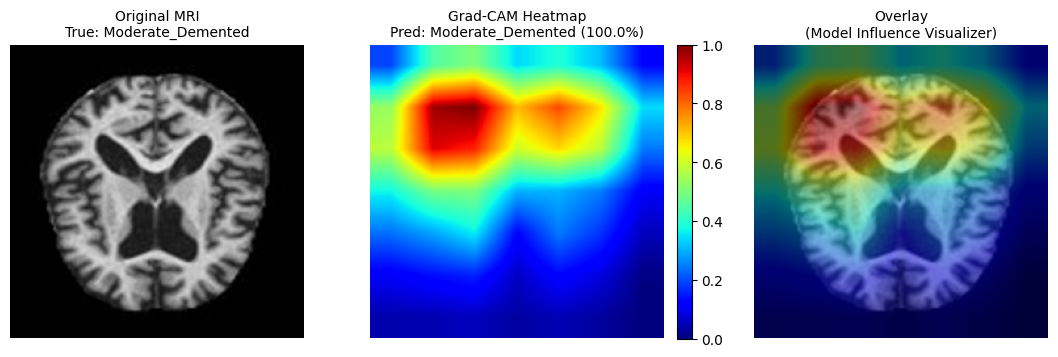


--- Moderate Demented Case #2 (moderate_45.jpg) ---


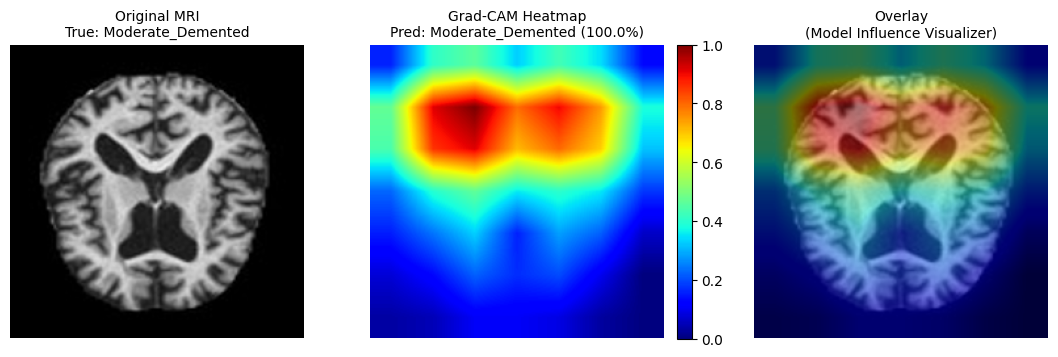


--- Moderate Demented Case #3 (moderate_56.jpg) ---


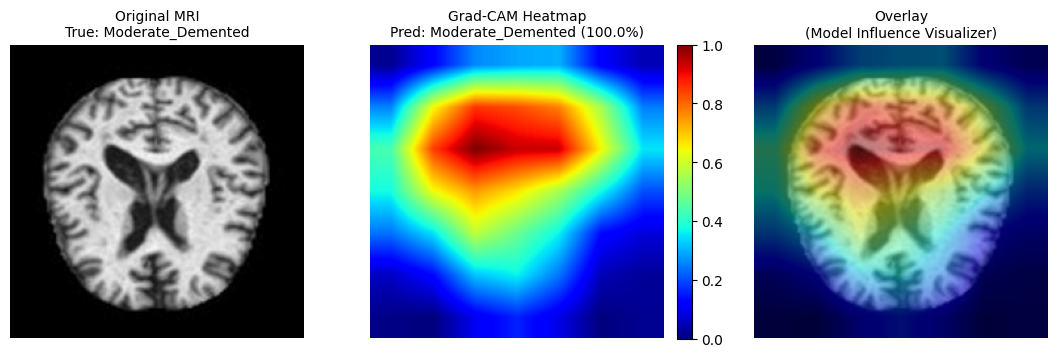


--- Moderate Demented Case #4 (moderate_5.jpg) ---


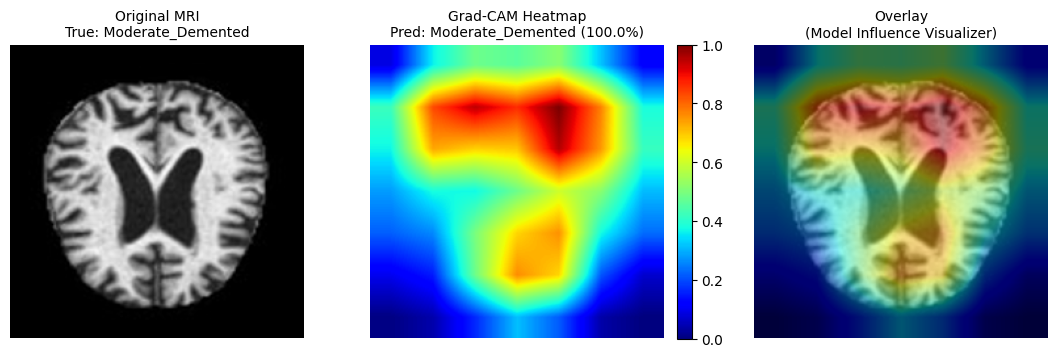


--- Moderate Demented Case #5 (moderate_32.jpg) ---


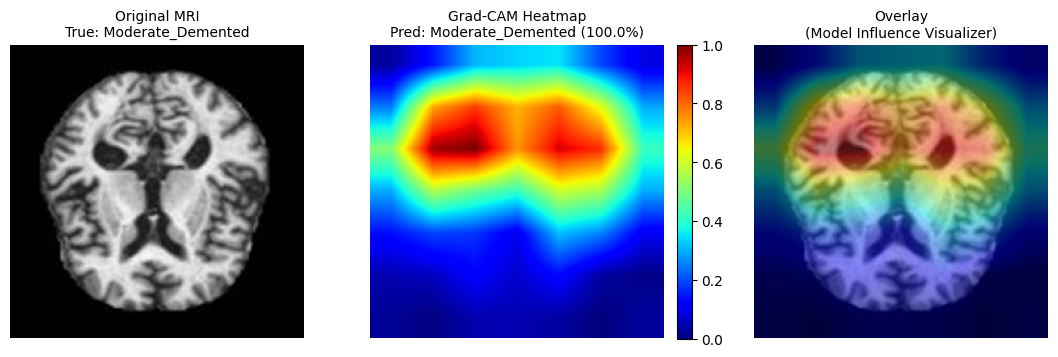


--- Moderate Demented Case #6 (moderate_53.jpg) ---


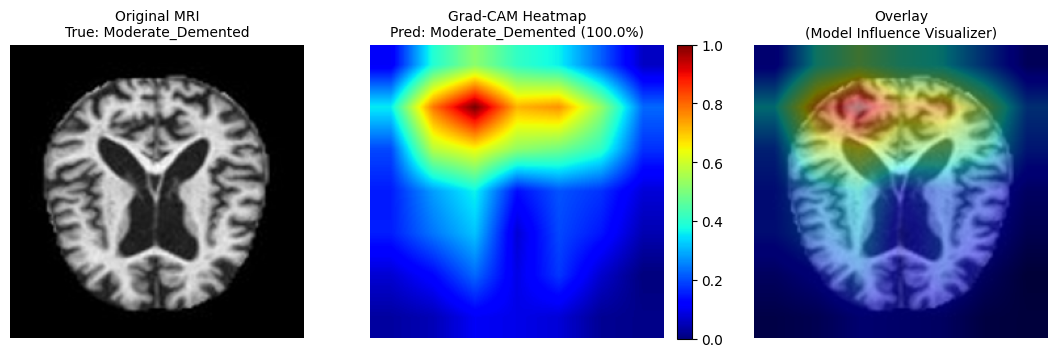


--- Moderate Demented Case #7 (moderate_42.jpg) ---


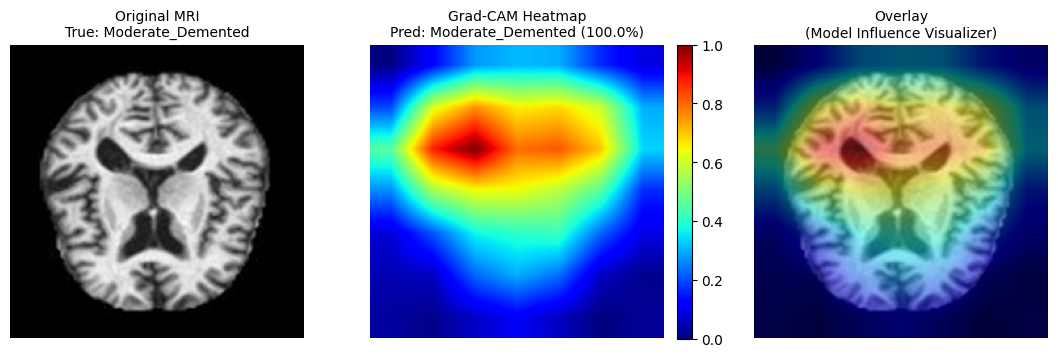


--- Moderate Demented Case #8 (moderate_14.jpg) ---


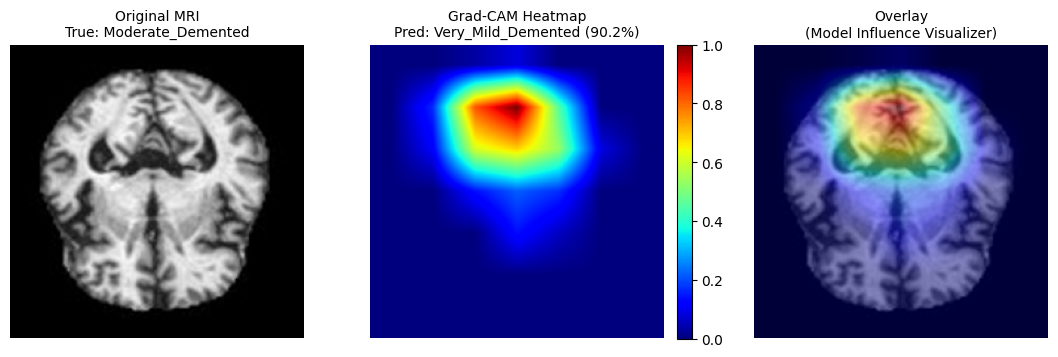


--- Moderate Demented Case #9 (moderate_16.jpg) ---


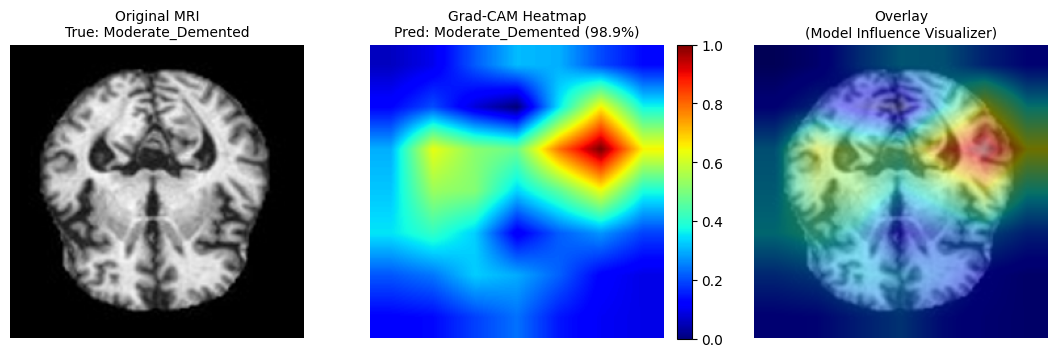

In [8]:
mod_idx = class_to_idx['Moderate_Demented']
mod_indices = [i for i, label in enumerate(test_labels) if label == mod_idx]

print(f"Visualizing all {len(mod_indices)} Moderate_Demented test cases:")
for rank, idx in enumerate(mod_indices, start=1):
    print(f"\n--- Moderate Demented Case #{rank} ({test_paths[idx].name}) ---")
    show_gradcam(test_paths[idx], true_label_idx=mod_idx)


## 9. Grad-CAM on Selected Predictions from Other Classes
Review representative scans from Mild, Very Mild, and Non Demented categories.



--- Correct Prediction Example: Mild_Demented (mild_889.jpg) ---


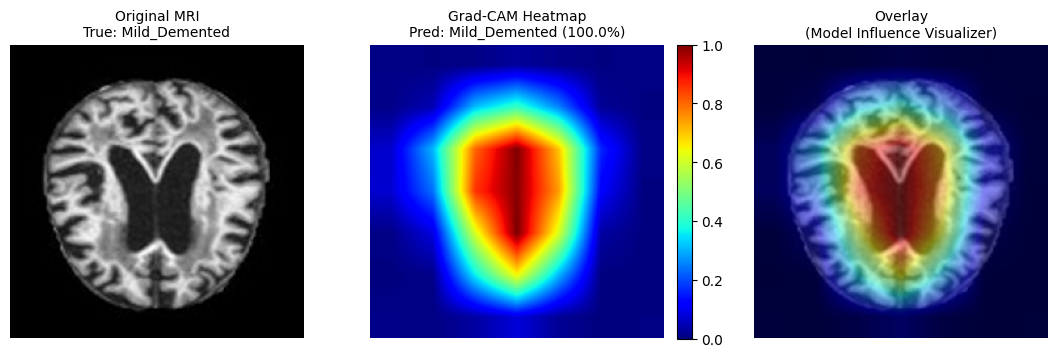


--- Correct Prediction Example: Very_Mild_Demented (verymild_1973.jpg) ---


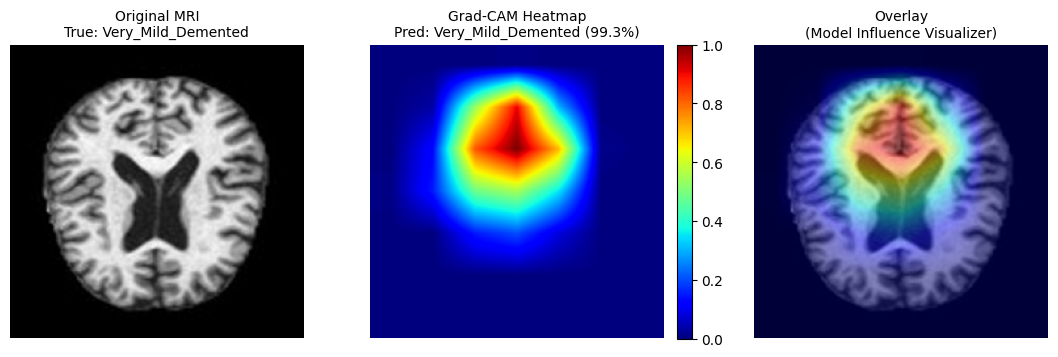


--- Correct Prediction Example: Non_Demented (non_1073.jpg) ---


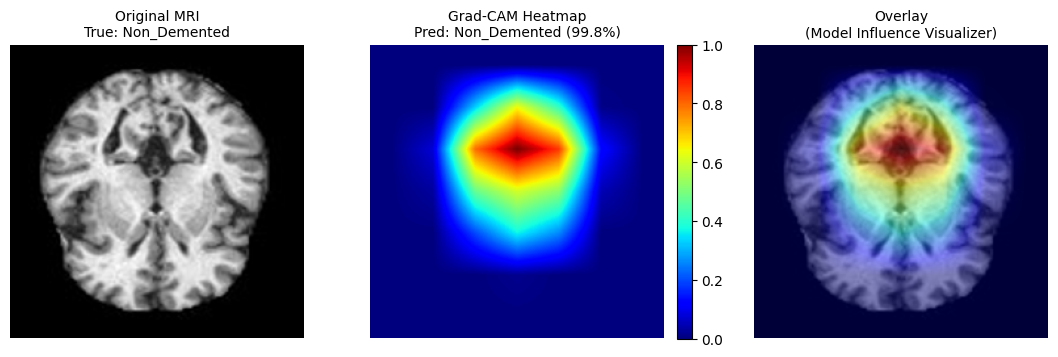


--- Misclassification Example (verymild_1669.jpg) ---


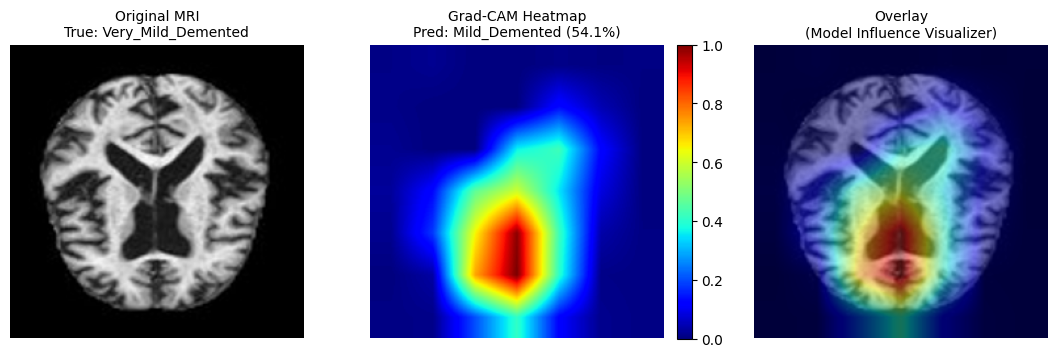

In [9]:
# Sample one correct prediction from each of the other three classes
other_classes = ['Mild_Demented', 'Very_Mild_Demented', 'Non_Demented']

for c_name in other_classes:
    c_idx = class_to_idx[c_name]
    # Find matching indices
    matching = [i for i in range(len(test_labels)) if test_labels[i] == c_idx and all_preds[i] == c_idx]
    if matching:
        sample_idx = matching[0]
        print(f"\n--- Correct Prediction Example: {c_name} ({test_paths[sample_idx].name}) ---")
        show_gradcam(test_paths[sample_idx], true_label_idx=c_idx)

# Sample an error case where prediction differed from true label if available
error_indices = [i for i in range(len(test_labels)) if test_labels[i] != all_preds[i]]
if error_indices:
    err_idx = error_indices[0]
    print(f"\n--- Misclassification Example ({test_paths[err_idx].name}) ---")
    show_gradcam(test_paths[err_idx], true_label_idx=test_labels[err_idx])
